In [1]:

!pip install -q transformers gradio pillow


In [3]:

import torch
from transformers import BlipProcessor, BlipForConditionalGeneration
from transformers.utils import logging
import warnings

warnings.filterwarnings("ignore")
logging.set_verbosity_error()

print("Loading BLIP model...")

processor = BlipProcessor.from_pretrained(
    "Salesforce/blip-image-captioning-base"
)

blip_model = BlipForConditionalGeneration.from_pretrained(
    "Salesforce/blip-image-captioning-base"
)

print("BLIP model loaded successfully!")


Loading BLIP model...


Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

BLIP model loaded successfully!


Saving image_caption.jpeg to image_caption (1).jpeg


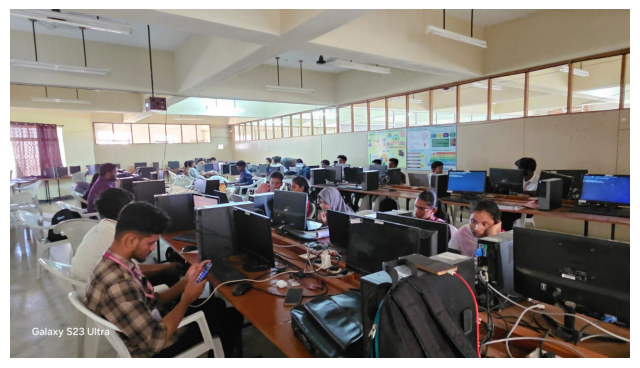

Image size: (1600, 900)


In [4]:

from google.colab import files
from PIL import Image
import matplotlib.pyplot as plt

uploaded = files.upload()

image_path = next(iter(uploaded))

image = Image.open(image_path).convert("RGB")

plt.figure(figsize=(8, 6))
plt.imshow(image)
plt.axis("off")
plt.show()

print("Image size:", image.size)



In [5]:

def get_caption(image):
    inputs = processor(
        image.convert("RGB"),
        return_tensors="pt"
    )

    with torch.no_grad():
        output = blip_model.generate(
            **inputs,
            max_new_tokens=50
        )

    caption = processor.decode(
        output[0],
        skip_special_tokens=True
    )

    return caption


print("Image captioning function is ready!")


Image captioning function is ready!


In [6]:

caption = get_caption(image)

print("Generated Image Caption:")
print(caption)

print("\nWord Count:", len(caption.split()))


Generated Image Caption:
a classroom with computers and people working on the computers

Word Count: 10


In [8]:

def get_caption_with_prompt(image, prompt):
    inputs = processor(
        image.convert("RGB"),
        text=prompt,
        return_tensors="pt"
    )

    with torch.no_grad():
        output = blip_model.generate(
            **inputs,
            max_new_tokens=50
        )

    return processor.decode(
        output[0],
        skip_special_tokens=True
    )


prompts = [
    "a photo of",
    "this image shows",
    "there are"
]

for prompt in prompts:
    result = get_caption_with_prompt(image, prompt)

    print("Prompt:", prompt)
    print("Caption:", result)
    print("-" * 50)


Prompt: a photo of
Caption: a photo of a classroom with computers and people
--------------------------------------------------
Prompt: this image shows
Caption: this image shows a classroom in the university of guli, in guli district, in guli district, in guli district, in
--------------------------------------------------
Prompt: there are
Caption: there are many people working in the office
--------------------------------------------------


In [9]:

token_lengths = [10, 20, 40, 60]

for max_t in token_lengths:
    inputs = processor(
        image.convert("RGB"),
        return_tensors="pt"
    )

    with torch.no_grad():
        output = blip_model.generate(
            **inputs,
            max_new_tokens=max_t
        )

    caption = processor.decode(
        output[0],
        skip_special_tokens=True
    )

    print(f"Max tokens: {max_t}")
    print("Caption:", caption)
    print("Word count:", len(caption.split()))
    print("-" * 50)



Max tokens: 10
Caption: a classroom with computers and people working on the computers
Word count: 10
--------------------------------------------------
Max tokens: 20
Caption: a classroom with computers and people working on the computers
Word count: 10
--------------------------------------------------
Max tokens: 40
Caption: a classroom with computers and people working on the computers
Word count: 10
--------------------------------------------------
Max tokens: 60
Caption: a classroom with computers and people working on the computers
Word count: 10
--------------------------------------------------


In [11]:

import gradio as gr

def caption_app(uploaded_image, prompt):
    if uploaded_image is None:
        return "Please upload an image first!"

    img = uploaded_image.convert("RGB")

    if prompt and prompt.strip():
        caption = get_caption_with_prompt(img, prompt)
    else:
        caption = get_caption(img)

    word_count = len(caption.split())

    return (
        f"Generated Caption:\n{caption}\n\n"
        f"Word Count: {word_count}"
    )


app = gr.Interface(
    fn=caption_app,
    inputs=[
        gr.Image(
            type="pil",
            label="Upload an Image"
        ),
        gr.Textbox(
            label="Optional Prompt",
            placeholder="Example: a photo of",
            lines=1
        )
    ],
    outputs=gr.Textbox(
        label="AI-Generated Caption",
        lines=4
    ),
    title="🖼️ AI Image Captioning",
    description=(
        "Upload an image and let AI describe it in English. "
        "You can optionally enter a starting prompt."
    )
)

app.launch(share=True)



Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://fa5c523fa253f2a833.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
